# Telco Customer Churn - 01. Exploratory Data Analysis
Steps 1-7: business problem, ML problem, dataset understanding, data quality, and EDA.

## 1. Understand the Business Problem
A telecom provider wants to reduce customer loss by identifying customers likely to churn.

In [1]:
import os, hashlib, warnings, platform, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             balanced_accuracy_score, RocCurveDisplay, PrecisionRecallDisplay, brier_score_loss)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.base import clone
from scipy.stats import loguniform, randint

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50, "display.width", 160)

In [2]:
# Business context
STAKEHOLDER = "Retention manager at the telecom provider"
DECISION = "Which customers should receive a retention offer this period?"
PRIMARY_LENS = "Churn risk"
SECONDARY_LENS = "High-risk customer profiling"

# Business assumptions (edit to match your group's report)
OFFER_COST   = 20.0   # cost to contact + offer one customer
SAVE_RATE    = 0.30   # fraction of contacted churners who are retained
VALUE_MONTHS = 12      # months of MonthlyCharges kept if a customer is saved

print("Stakeholder:", STAKEHOLDER)
print("Decision:", DECISION)
print("Primary lens:", PRIMARY_LENS, "| Secondary lens:", SECONDARY_LENS)

Stakeholder: Retention manager at the telecom provider
Decision: Which customers should receive a retention offer this period?
Primary lens: Churn risk | Secondary lens: High-risk customer profiling


## 2. Define the ML Problem
Binary classification: predict churn probability, then rank/flag customers.

In [3]:
TASK = "Binary classification (churn probability, used for ranking + a decision threshold)"
UNIT_OF_ANALYSIS = "One customer (snapshot, no dates in the data)"
SUCCESS_METRIC = "PR-AUC / ROC-AUC for ranking quality; expected net benefit at the chosen threshold"

print("Task:", TASK)
print("Unit of analysis:", UNIT_OF_ANALYSIS)
print("Success metric:", SUCCESS_METRIC)

Task: Binary classification (churn probability, used for ranking + a decision threshold)
Unit of analysis: One customer (snapshot, no dates in the data)
Success metric: PR-AUC / ROC-AUC for ranking quality; expected net benefit at the chosen threshold


## 3. Understand the Dataset
Load the CSV, record its fingerprint, and build a data dictionary.

In [4]:
from google.colab import files

uploaded = files.upload()
EXPECTED_FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
assert EXPECTED_FILE in uploaded, f"Please upload {EXPECTED_FILE}"

DATA_PATH = Path(EXPECTED_FILE)

sha = hashlib.sha256(open(DATA_PATH, "rb").read()).hexdigest()
print("File:", DATA_PATH)
print("SHA-256:", sha)
print("Python", platform.python_version(), "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

File: WA_Fn-UseC_-Telco-Customer-Churn.csv
SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a
Python 3.12.3 | pandas 3.0.2 | scikit-learn 1.8.0


In [5]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
display(raw.head())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
data_dictionary = pd.DataFrame([
 ("customerID","Unique customer identifier","ID"),
 ("gender","Customer gender","categorical"),
 ("SeniorCitizen","Senior citizen flag","binary (numeric)"),
 ("Partner","Has a partner","binary"),
 ("Dependents","Has dependents","binary"),
 ("tenure","Months as a customer","numeric"),
 ("PhoneService","Has phone service","binary"),
 ("MultipleLines","Has multiple phone lines","categorical"),
 ("InternetService","Internet service type","categorical"),
 ("OnlineSecurity","Online security add-on","categorical"),
 ("OnlineBackup","Online backup add-on","categorical"),
 ("DeviceProtection","Device protection add-on","categorical"),
 ("TechSupport","Tech support add-on","categorical"),
 ("StreamingTV","Streams TV","categorical"),
 ("StreamingMovies","Streams movies","categorical"),
 ("Contract","Contract type","categorical"),
 ("PaperlessBilling","Uses paperless billing","binary"),
 ("PaymentMethod","How the customer pays","categorical"),
 ("MonthlyCharges","Current monthly bill","numeric"),
 ("TotalCharges","Total billed to date (stored as text)","numeric"),
 ("Churn","TARGET: customer left","binary"),
], columns=["column","meaning","type"])
display(data_dictionary)

,column,meaning,type
0,customerID,Unique customer identifier,ID
1,gender,Customer gender,categorical
2,SeniorCitizen,Senior citizen flag,binary (numeric)
3,Partner,Has a partner,binary
4,Dependents,Has dependents,binary
5,tenure,Months as a customer,numeric
6,PhoneService,Has phone service,binary
7,MultipleLines,Has multiple phone lines,categorical
8,InternetService,Internet service type,categorical
9,OnlineSecurity,Online security add-on,categorical


## 4. Data Quality Checking
Check duplicates, missing values, wrong types, and consistency between related columns.

In [7]:
print("Duplicate rows:", raw.duplicated().sum())
print("Duplicate customerID:", raw.customerID.duplicated().sum())
print("TotalCharges dtype:", raw.TotalCharges.dtype)

blank = raw.TotalCharges.astype(str).str.strip().eq("")
print("Blank TotalCharges:", blank.sum())
display(raw.loc[blank, ["customerID","tenure","MonthlyCharges","Contract","Churn"]])

Duplicate rows: 0
Duplicate customerID: 0
TotalCharges dtype: str
Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,Contract,Churn
488,4472-LVYGI,0,52.55,Two year,No
753,3115-CZMZD,0,20.25,Two year,No
936,5709-LVOEQ,0,80.85,Two year,No
1082,4367-NUYAO,0,25.75,Two year,No
1340,1371-DWPAZ,0,56.05,Two year,No
3331,7644-OMVMY,0,19.85,Two year,No
3826,3213-VVOLG,0,25.35,Two year,No
4380,2520-SGTTA,0,20.00,Two year,No
5218,2923-ARZLG,0,19.70,One year,No
6670,4075-WKNIU,0,73.35,Two year,No


In [8]:
ADDONS = ["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]
c1 = ((raw.MultipleLines == "No phone service") == (raw.PhoneService == "No")).all()
c2 = all(((raw[c] == "No internet service") == (raw.InternetService == "No")).all() for c in ADDONS)
print("'No phone service' matches PhoneService=No:", c1)
print("'No internet service' matches InternetService=No:", c2)

'No phone service' matches PhoneService=No: True
'No internet service' matches InternetService=No: True


In [9]:
tmp = raw.assign(TotalCharges=pd.to_numeric(raw.TotalCharges.astype(str).str.strip().replace("", np.nan)))
display(tmp[["tenure","MonthlyCharges","TotalCharges"]].describe().round(2))
print("corr(tenure, TotalCharges):", round(tmp.tenure.corr(tmp.TotalCharges), 3))

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


corr(tenure, TotalCharges): 0.826


## 5. Exploratory Data Analysis — quick look (full data)
A first pass on the whole dataset before splitting.

Overall churn rate: 0.2654


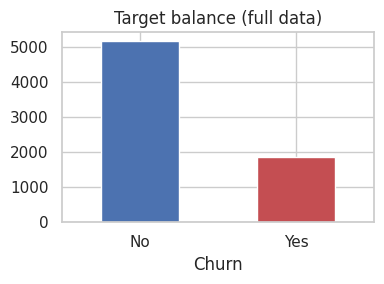

In [10]:
df0 = raw.copy()
df0["TotalCharges"] = pd.to_numeric(df0.TotalCharges.astype(str).str.strip().replace("", np.nan), errors="coerce").fillna(0.0)
df0["ChurnFlag"] = (df0.Churn == "Yes").astype(int)

print("Overall churn rate:", round(df0.ChurnFlag.mean(), 4))
fig, ax = plt.subplots(figsize=(4,3))
df0.Churn.value_counts().plot.bar(ax=ax, color=["#4C72B0","#C44E52"]); ax.set_title("Target balance (full data)")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

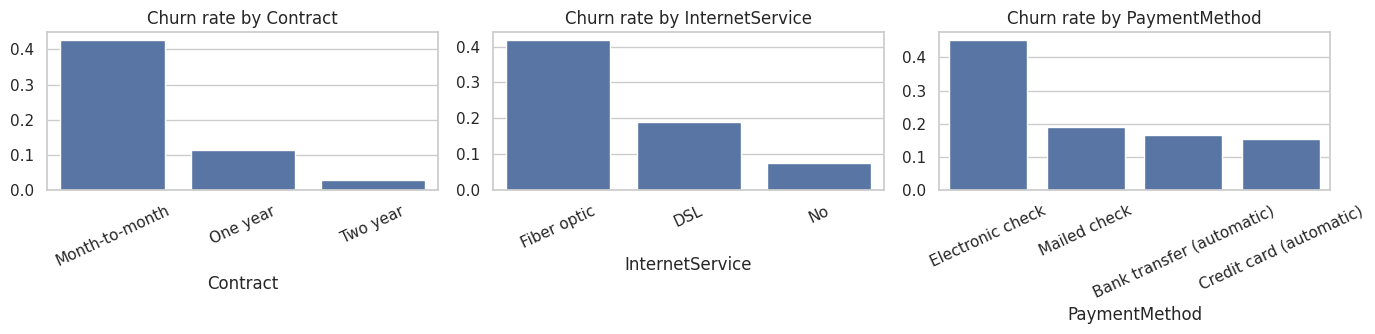

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    r = df0.groupby(c).ChurnFlag.mean().sort_values(ascending=False)
    sns.barplot(x=r.index.astype(str), y=r.values, ax=ax, color="#4C72B0")
    ax.set_title(f"Churn rate by {c}"); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

## 6. Train/Test Split
Split 80/20, stratified on Churn, before any deeper analysis or preprocessing.

In [12]:
y = df0["ChurnFlag"]
X = df0.drop(columns=["customerID", "Churn", "ChurnFlag"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "churn rate:", round(y_train.mean(), 4))
print("Test :", X_test.shape, "churn rate:", round(y_test.mean(), 4))

Train: (5634, 19) churn rate: 0.2654
Test : (1409, 19) churn rate: 0.2654


## 7. Exploratory Data Analysis — deeper look (train only)
All further analysis uses the training set only; the test set stays untouched.

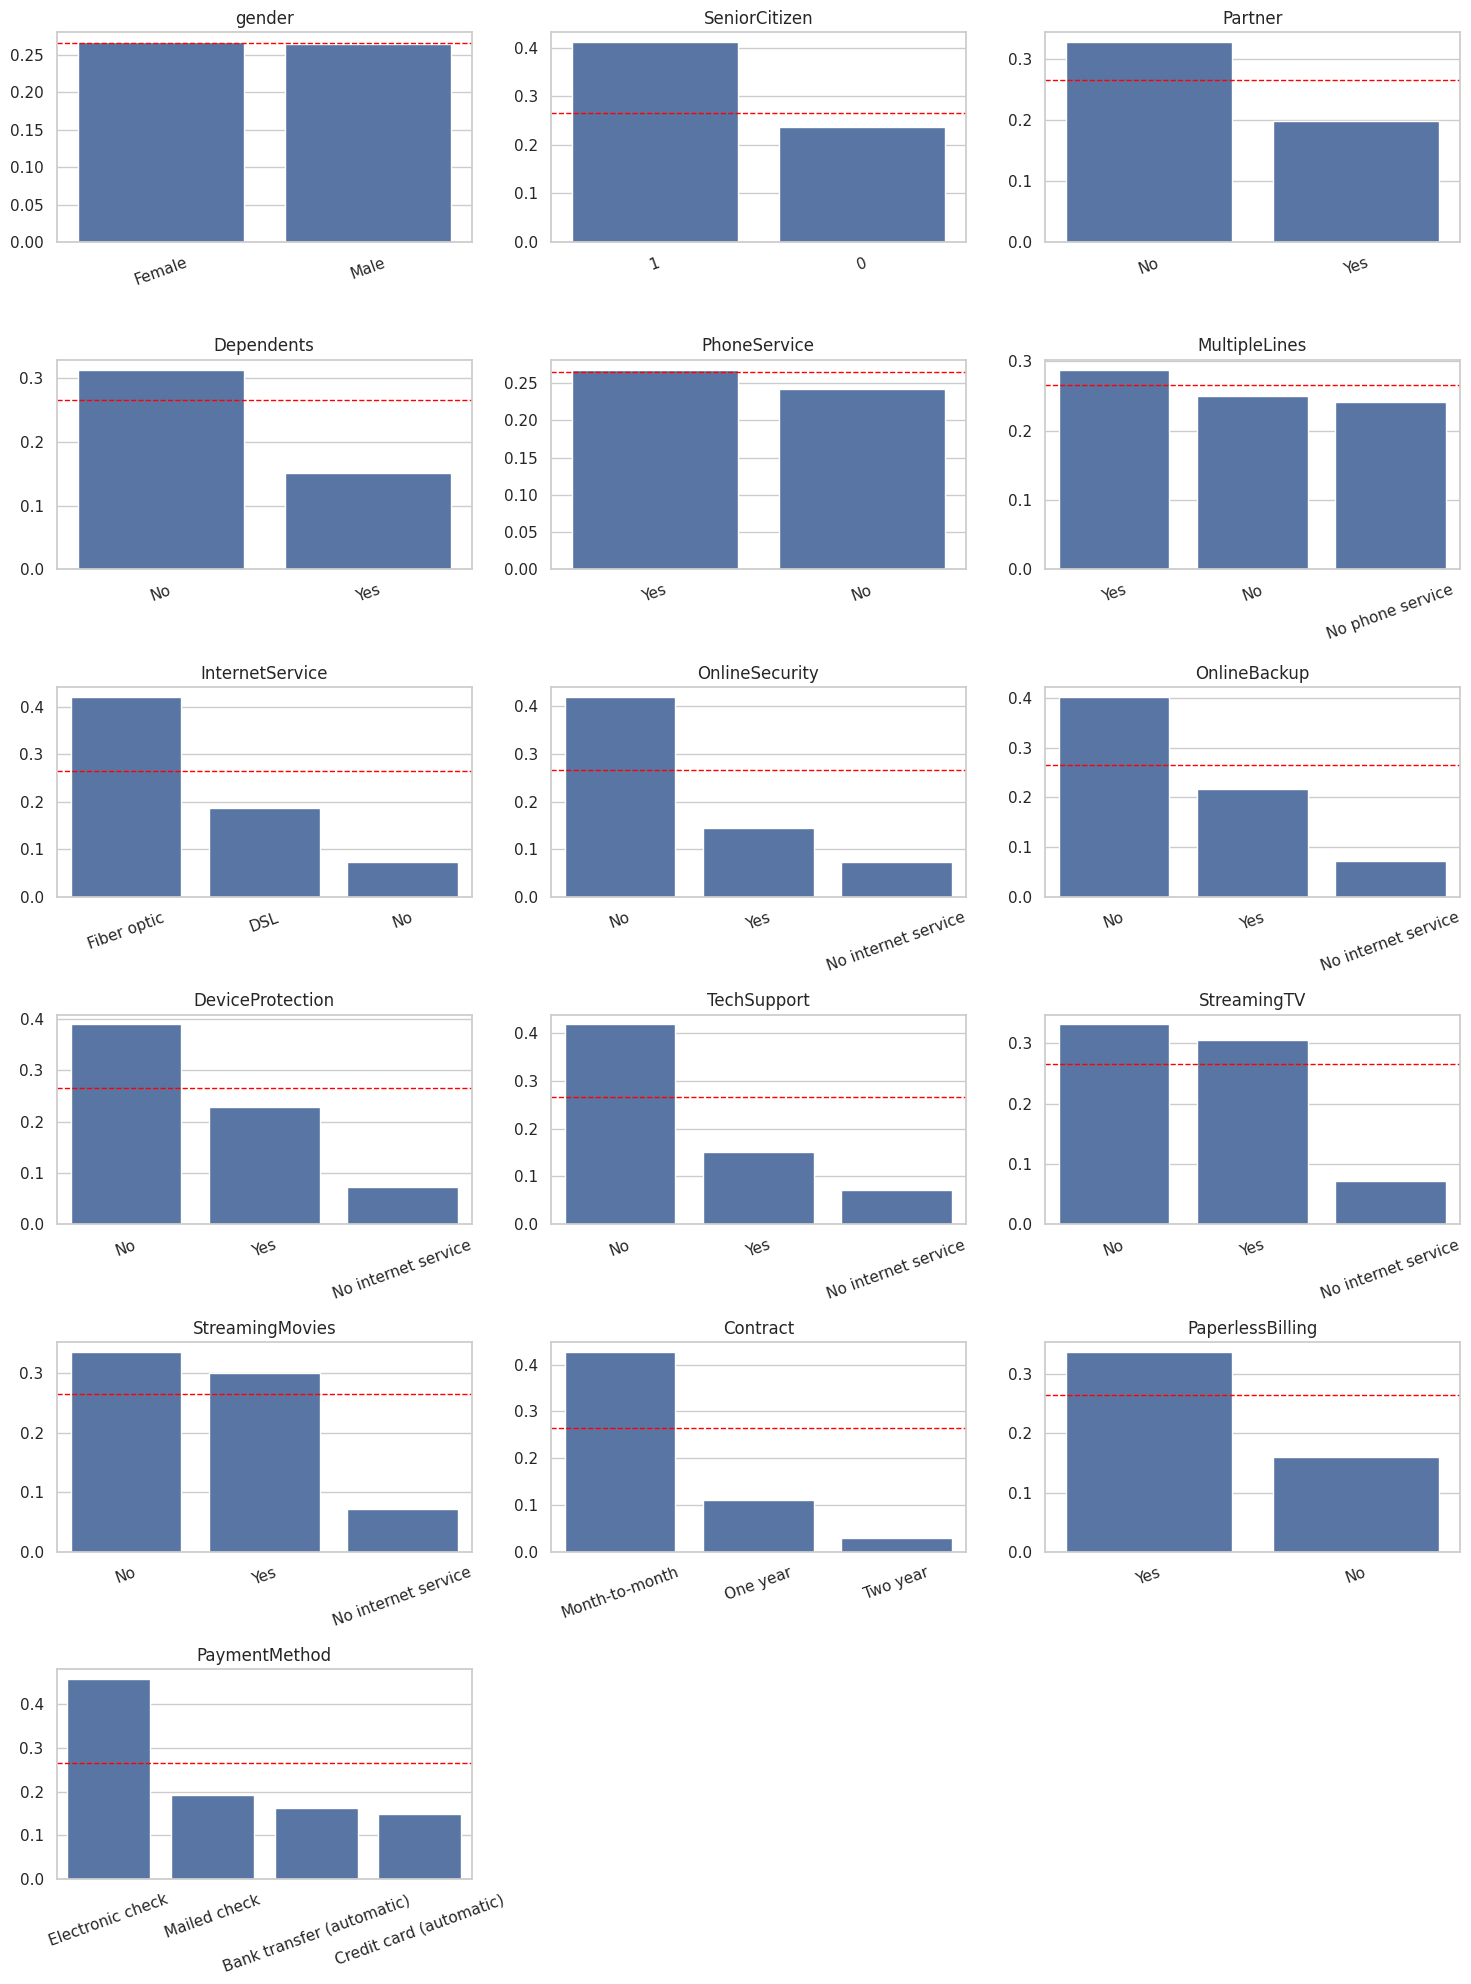

In [13]:
train = X_train.assign(Churn=y_train)
CAT_EDA = ["gender","SeniorCitizen","Partner","Dependents","PhoneService","MultipleLines","InternetService"] + ADDONS + \
          ["Contract","PaperlessBilling","PaymentMethod"]
NUM_EDA = ["tenure","MonthlyCharges","TotalCharges"]

fig, axes = plt.subplots(6, 3, figsize=(15, 20)); overall = train.Churn.mean()
for ax, c in zip(axes.ravel(), CAT_EDA):
    r = train.groupby(c)["Churn"].mean().sort_values(ascending=False)
    sns.barplot(x=r.index.astype(str), y=r.values, ax=ax, color="#4C72B0")
    ax.axhline(overall, color="red", ls="--", lw=1); ax.set_title(c); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
for ax in axes.ravel()[len(CAT_EDA):]: ax.axis("off")
plt.tight_layout(); plt.show()

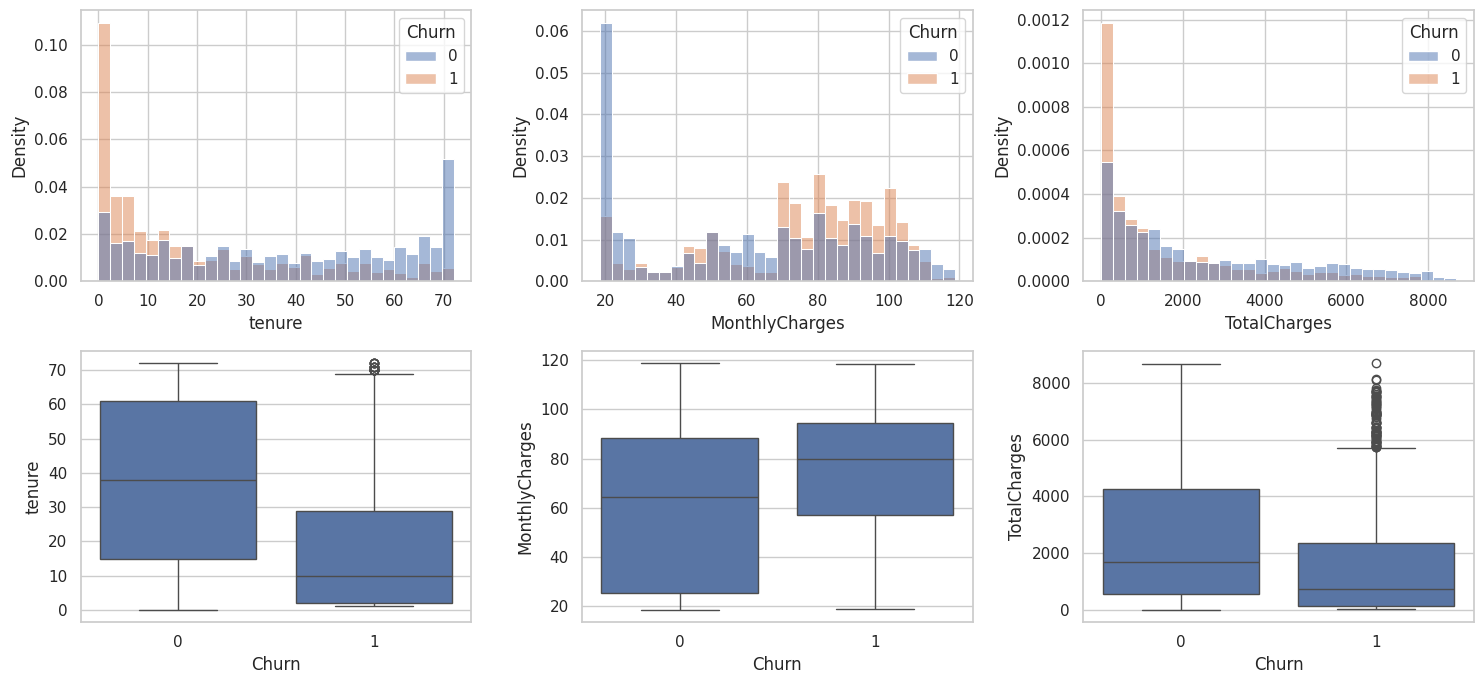

,mean,count
tenure_band,,
0-12,0.473,1737
13-24,0.286,818
25-48,0.202,1290
49-72,0.099,1789


In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for j, c in enumerate(NUM_EDA):
    sns.histplot(data=train, x=c, hue="Churn", bins=30, stat="density", common_norm=False, ax=axes[0, j])
    sns.boxplot(data=train, x="Churn", y=c, ax=axes[1, j])
plt.tight_layout(); plt.show()

train["tenure_band"] = pd.cut(train.tenure, [-1, 12, 24, 48, 72], labels=["0-12","13-24","25-48","49-72"])
display(train.groupby("tenure_band", observed=True).Churn.agg(["mean","count"]).round(3))

In [15]:
rows = []
for c in CAT_EDA:
    ct = pd.crosstab(train[c], train.Churn); chi2, p, dof, _ = stats.chi2_contingency(ct)
    rows.append((c, p, np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))))
for c in NUM_EDA:
    a, b = train.loc[train.Churn == 1, c], train.loc[train.Churn == 0, c]
    u, p = stats.mannwhitneyu(a, b); rows.append((c, p, 1 - 2*u/(len(a)*len(b))))
assoc = pd.DataFrame(rows, columns=["feature","p_value","effect_size"]).sort_values("p_value")
display(assoc.round(4).reset_index(drop=True))

,feature,p_value,effect_size
0,Contract,0.0000,0.4111
1,tenure,0.0000,0.4704
2,OnlineSecurity,0.0000,0.3510
3,TechSupport,0.0000,0.3449
4,InternetService,0.0000,0.3266
5,PaymentMethod,0.0000,0.3111
6,OnlineBackup,0.0000,0.2943
7,DeviceProtection,0.0000,0.2799
8,StreamingMovies,0.0000,0.2317
9,StreamingTV,0.0000,0.2304


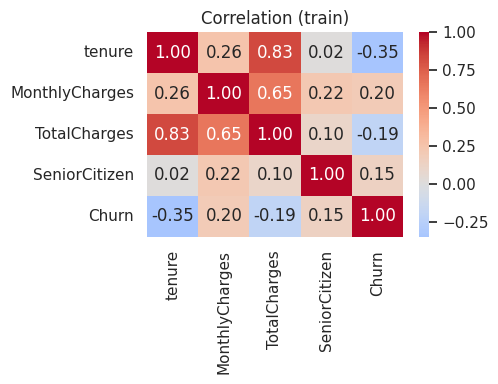

In [16]:
plt.figure(figsize=(5, 4))
sns.heatmap(train[NUM_EDA + ["SeniorCitizen", "Churn"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation (train)"); plt.tight_layout(); plt.show()